Note: you may need to restart the kernel to use updated packages.


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

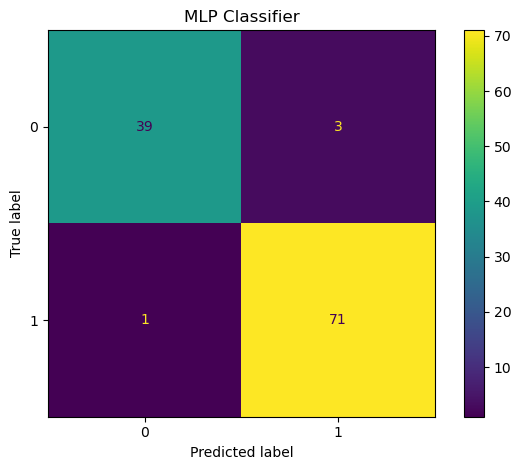

Saved: mlp_classifier.joblib


In [1]:
#MLP
%pip install scikit-learn matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, classification_report,
 confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X, y = df.drop(columns=["target"]), df["target"]
print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\n", y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = Pipeline([
 ("scale", StandardScaler()),
 ("classifier", MLPClassifier(hidden_layer_sizes=(64,), max_iter=500,
 early_stopping=True, random_state=42))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("\nClassification report:\n", classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1 score:", f1_score(y_test, pred, average="weighted", zero_division=0))
cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("MLP Classifier")
plt.tight_layout()
plt.show()
joblib.dump(model, "mlp_classifier.joblib")
print("Saved: mlp_classifier.joblib")

In [2]:
#CNN
%pip install tensorflow scikit-learn matplotlib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X, y = load_digits(return_X_y=True)
X = (X.reshape(-1, 8, 8, 1) / 16.0).astype("float32")
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = models.Sequential([
 layers.Input(shape=(8, 8, 1)),
 layers.Conv2D(16, 3, activation="relu", padding="same"),
 layers.MaxPooling2D(2),
 layers.Flatten(),
 layers.Dense(64, activation="relu"),
 layers.Dense(10, activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
 metrics=["accuracy"])
model.fit(X_train, y_train, epochs=10, batch_size=32,
 validation_split=0.1, verbose=1)
pred = model.predict(X_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
model.save("cnn_digits.keras")
print("Saved: cnn_digits.keras")

Note: you may need to restart the kernel to use updated packages.
Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.4702 - loss: 2.0729 - val_accuracy: 0.7639 - val_loss: 1.8076
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7966 - loss: 1.4063 - val_accuracy: 0.8958 - val_loss: 1.0357
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8979 - loss: 0.7295 - val_accuracy: 0.9167 - val_loss: 0.5620
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9250 - loss: 0.4050 - val_accuracy: 0.9236 - val_loss: 0.3787
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9397 - loss: 0.2891 - val_accuracy: 0.9375 - val_loss: 0.2901
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9528 - loss: 0.2180 - val_accuracy: 0.9375 - val_loss: 0.2343
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9520 - loss: 0.1861 - val_accuracy: 0.9583 - val_loss: 0.2094
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 

In [4]:
#RNN
%pip install tensorflow scikit-learn
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rng = np.random.default_rng(42)
X = rng.normal(0, 0.25, (1000, 20, 1)).astype("float32")
y = np.array([0]*500 + [1]*500)
X[500:, :, 0] += np.linspace(-0.8, 0.8, 20)
idx = rng.permutation(len(y))
X, y = X[idx], y[idx]
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = models.Sequential([
 layers.Input(shape=(20, 1)),
 layers.SimpleRNN(32),
 layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=10, batch_size=32,
 validation_split=0.1, verbose=1)
pred = (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
model.save("rnn_sequence.keras")
print("Saved: rnn_sequence.keras")

Note: you may need to restart the kernel to use updated packages.
Epoch 1/10


23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.8903 - loss: 0.3587 - val_accuracy: 0.9875 - val_loss: 0.1834
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9986 - loss: 0.1019 - val_accuracy: 1.0000 - val_loss: 0.0504
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9986 - loss: 0.0389 - val_accuracy: 0.9875 - val_loss: 0.0437
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9958 - loss: 0.0383 - val_accuracy: 1.0000 - val_loss: 0.0278
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0255 - val_accuracy: 1.0000 - val_loss: 0.0190
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.0159 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0114 - val_accuracy: 1.0000 - val_loss: 0.0097
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.0090 - val_accuracy: 1.0000 - val_loss: 0.

In [5]:
#LSTM
%pip install tensorflow scikit-learn
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
rng = np.random.default_rng(42)
X = rng.normal(0, 0.25, (1000, 20, 1)).astype("float32")
y = np.array([0]*500 + [1]*500)
X[500:, :, 0] += np.linspace(-0.8, 0.8, 20)
idx = rng.permutation(len(y))
X, y = X[idx], y[idx]
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = models.Sequential([
 layers.Input(shape=(20, 1)),
 layers.LSTM(32),
 layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=10, batch_size=32,
 validation_split=0.1, verbose=1)
pred = (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
model.save("lstm_sequence.keras")
print("Saved: lstm_sequence.keras")

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: tensorflow in c:\users\praja\appdata\roaming\python\python312\site-packages (2.21.0)

Epoch 1/10


23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.5333 - loss: 0.6798 - val_accuracy: 0.8125 - val_loss: 0.6462
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9139 - loss: 0.6083 - val_accuracy: 0.9375 - val_loss: 0.5503
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9694 - loss: 0.4216 - val_accuracy: 0.9875 - val_loss: 0.1958
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0638 - val_accuracy: 1.0000 - val_loss: 0.0167
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0112 - val_accuracy: 1.0000 - val_loss: 0.0086
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 1.0000 - loss: 0.0068 - val_accuracy: 1.0000 - val_loss: 0.0057
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 1.0000 - val_loss: 0.0043
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0038 - val_accuracy: 1.0000 - val_loss: 0.

In [6]:
#GRU
%pip install tensorflow scikit-learn
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
rng = np.random.default_rng(42)
X = rng.normal(0, 0.25, (1000, 20, 1)).astype("float32")
y = np.array([0]*500 + [1]*500)
X[500:, :, 0] += np.linspace(-0.8, 0.8, 20)
idx = rng.permutation(len(y))
X, y = X[idx], y[idx]
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = models.Sequential([
 layers.Input(shape=(20, 1)),
 layers.GRU(32),
 layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=10, batch_size=32,
 validation_split=0.1, verbose=1)
pred = (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
model.save("gru_sequence.keras")
print("Saved: gru_sequence.keras")

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: tensorflow in c:\users\praja\appdata\roaming\python\python312\site-packages (2.21.0)

Epoch 1/10


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.8611 - loss: 0.6617 - val_accuracy: 0.8500 - val_loss: 0.6155
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9611 - loss: 0.5676 - val_accuracy: 0.9500 - val_loss: 0.4984
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9861 - loss: 0.4144 - val_accuracy: 0.9875 - val_loss: 0.3118
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9958 - loss: 0.2027 - val_accuracy: 1.0000 - val_loss: 0.1012
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9931 - loss: 0.0685 - val_accuracy: 0.9875 - val_loss: 0.0785
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9917 - loss: 0.0459 - val_accuracy: 1.0000 - val_loss: 0.0352
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9986 - loss: 0.0290 - val_accuracy: 1.0000 - val_loss: 0.0244
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9944 - loss: 0.0304 - val_accuracy: 1.0000 - val_loss: 0.

In [7]:
#Transformers
%pip install transformers torch scikit-learn

from transformers import pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
texts = [
 "I loved this movie", "Amazing and wonderful story", "Very enjoyable film",
 "The acting was excellent", "I would watch it again", "A brilliant movie",
 "I hated this movie", "Awful and boring story", "Very disappointing film",
 "The acting was terrible", "I would not watch it again", "A dreadful movie",
 "Fantastic performance", "A great experience", "Bad and poorly made",
 "Waste of time", "Really good", "Really bad", "Beautiful and touching",
 "Slow and irritating"
]
labels = [1]*6 + [0]*6 + [1]*2 + [0]*2 + [1]*2 + [0]*2
X_train, X_test, y_train, y_test = train_test_split(
 texts, labels, test_size=0.30, random_state=42, stratify=labels)

classifier = pipeline(
 "text-classification",
 model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)
pred = []
for text in X_test:
 result = classifier(text)[0]
 pred.append(1 if result["label"].upper() == "POSITIVE" else 0)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: transformers in c:\users\praja\anaconda3\lib\site-packages (4.46.3)


              precision    recall  f1-score   support

           0       0.75      1.00      0.86         3
           1       1.00      0.67      0.80         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6

Accuracy: 0.8333333333333334
Confusion matrix:
 [[3 0]
 [1 2]]
